# Experiment 9: Density-Based Clustering using DBSCAN
**Aim:** Use DBSCAN to find clusters of any shape and identify noise points.

**Dataset:** Two Moons (generated with scikit-learn): 500 points in two curved clusters + 50 random noise points = 550 points.

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans
import warnings
warnings.filterwarnings("ignore")

Shape: (550, 2)


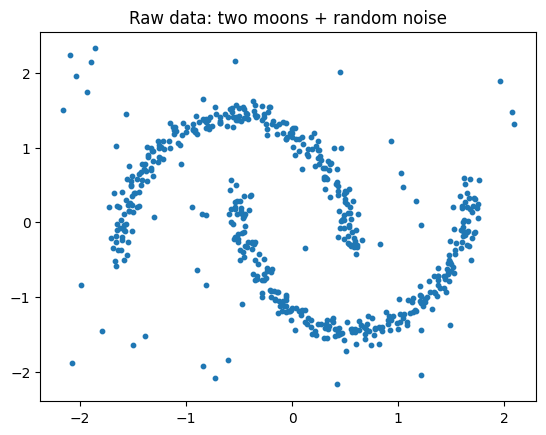

In [3]:
X, _ = make_moons(n_samples=500, noise=0.05, random_state=42)

rng = np.random.RandomState(42)
noise = rng.uniform(low=[-1.5, -1], high=[2.5, 1.5], size=(50, 2))     # 50 random noise points
X = np.vstack([X, noise])

X = StandardScaler().fit_transform(X)
print("Shape:", X.shape)

plt.scatter(X[:, 0], X[:, 1], s=10)
plt.title("Raw data: two moons + random noise")
plt.show()

## Choose eps using the k-distance graph (k = min_samples = 5). Pick eps where the curve bends sharply (the knee).

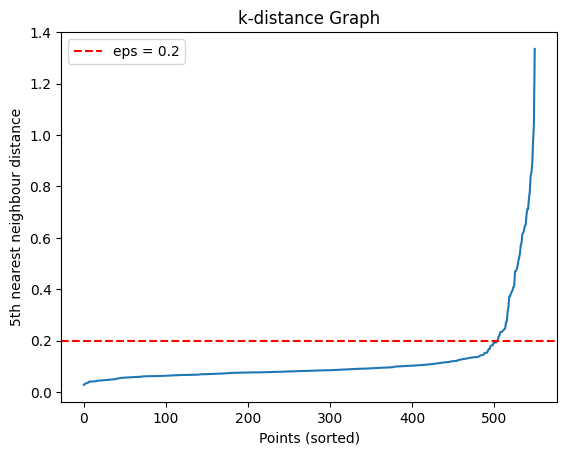

In [4]:
nn = NearestNeighbors(n_neighbors=5)
nn.fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, 4])         # distance to the 5th nearest neighbour, sorted

plt.plot(k_dist)
plt.axhline(0.2, color="red", linestyle="--", label="eps = 0.2")
plt.xlabel("Points (sorted)")
plt.ylabel("5th nearest neighbour distance")
plt.title("k-distance Graph")
plt.legend()
plt.show()

## Apply DBSCAN

In [5]:
db = DBSCAN(eps=0.2, min_samples=5)
labels = db.fit_predict(X)                # label -1 means noise

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
n_core = len(db.core_sample_indices_)

print("Clusters found :", n_clusters)
print("Core points    :", n_core)
print("Border points  :", len(X) - n_core - n_noise)
print("Noise points   :", n_noise)

Clusters found : 2
Core points    : 504
Border points  : 10
Noise points   : 36


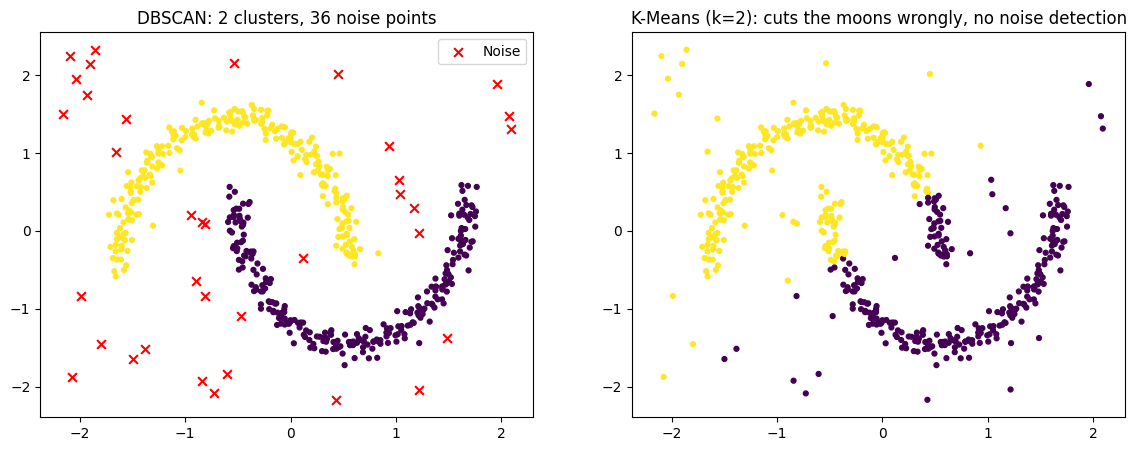

In [6]:
kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(X[labels != -1, 0], X[labels != -1, 1], c=labels[labels != -1], cmap="viridis", s=12)
ax[0].scatter(X[labels == -1, 0], X[labels == -1, 1], c="red", marker="x", s=40, label="Noise")
ax[0].set_title(f"DBSCAN: {n_clusters} clusters, {n_noise} noise points")
ax[0].legend()

ax[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=12)
ax[1].set_title("K-Means (k=2): cuts the moons wrongly, no noise detection")
plt.show()

## Effect of eps

In [7]:
rows = []
for eps in [0.1, 0.2, 0.3, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows.append([eps, len(set(lab)) - (1 if -1 in lab else 0), list(lab).count(-1)])

pd.DataFrame(rows, columns=["eps", "Clusters", "Noise points"])

,eps,Clusters,Noise points
0,0.1,9,89
1,0.2,2,36
2,0.3,2,30
3,0.5,1,13


## Conclusion
DBSCAN found the **2 moon-shaped clusters** correctly and marked the scattered points as **noise (label −1)** without being told the number of clusters. K-Means cannot follow curved shapes and puts every point in some cluster. A small eps gives many tiny clusters and lots of noise, and a large eps merges everything. The k-distance graph helps pick a good eps (≈0.2 here).